# Gold-news sentiment 01: data, splits and gates (no model)

Registration draft: `docs/sentiment/PREREG_SENTIMENT.md` (§2 data, §3 gates; **not approved**).
This notebook runs the data steps in order and shows their tables and plots. All logic lives in
`app/research/sentiment/data.py` and `gates.py` (tested in `tests/test_sentiment_data.py`); the
notebook only calls them. The same results come from the command line:

```
python -m app research sentiment data
python -m app research sentiment gates
```

Rules followed here: no model is trained, scored or loaded; no statistic joins a headline (or
its label) with a price or a volatility; **no headline text is printed** (licence CC BY-NC-ND
4.0; `gates.md` quotes four, the limit is five); the price reader stops before the lockbox
start (2026-01-10).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from app.research.sentiment import data as sd
from app.research.sentiment import gates as sg

pd.set_option("display.width", 120)
cfg = sd.load_config()
print(
    f"config {cfg.path.name}: near Jaccard {cfg.near_jaccard}, window {cfg.window_days} days, "
    f"min test {cfg.min_test}, prices from {cfg.price_first} to before {cfg.price_stop}"
)

config sentiment.toml: near Jaccard 0.8, window 3 days, min test 1500, prices from 2003-01-01 to before 2026-01-10


## Step 0: check the raw files

Every raw file must match the SHA-256 recorded in `app/config/sentiment.toml`; a mismatch stops
the run, so every figure below comes from exactly these bytes. Stooq (the G2 cross-check) is
optional and missing: its URL answered 404 on 2026-11-18.

In [2]:
status = sd.verify_files(cfg)
pd.DataFrame(
    [
        {"file": k, "status": status[k], "sha256": f.sha256[:16] + "..." if f.sha256 else "-"}
        for k, f in cfg.files.items()
    ]
)

,file,status,sha256
0,gold_zip,ok,eb78715777d15bee...
1,gold,ok,1c2d032de29c0080...
2,fpb_zip,ok,0e1a06c4900fdae4...
3,fpb,ok,5fb370b3005b9a27...
4,dukascopy,ok,2e3567e8f6c7b3e1...
5,stooq,missing,-


## Step 2: load and normalise the gold headlines

Columns are mapped to tidy names; the training label is the dataset's Price Sentiment with
`none -> neutral` and an `is_none` flag (PREREG §2.2). Dates must be `DD-MM-YYYY`; rows that do
not parse are dropped and reported. As evidence on the date column we count days above 12 (so
the order is day-month) and compare with the date many article URLs carry.

In [3]:
gold, unparsable = sd.load_gold(cfg.files["gold"].path)
checks = sd.date_checks(gold, unparsable)
n_bad = len(unparsable)
print(f"rows in file {len(gold) + n_bad:,}; dated {len(gold):,}; unparsable {n_bad}")
print(f"date range {gold['date'].min().date()} to {gold['date'].max().date()}")
pd.Series(checks, name="value").to_frame()

rows in file 10,570; dated 10,405; unparsable 165
date range 2000-02-15 to 2019-02-01


,value
day_field_gt12,6275
url_date_rows,5400
url_date_equal,5338
unparsable_shapes,{'9999-99-99': 165}
unparsable_url_date,161
unparsable_url_mmdd_match,160


,positive,negative,neutral,none
all dated,41.6%,36.1%,3.6%,18.7%


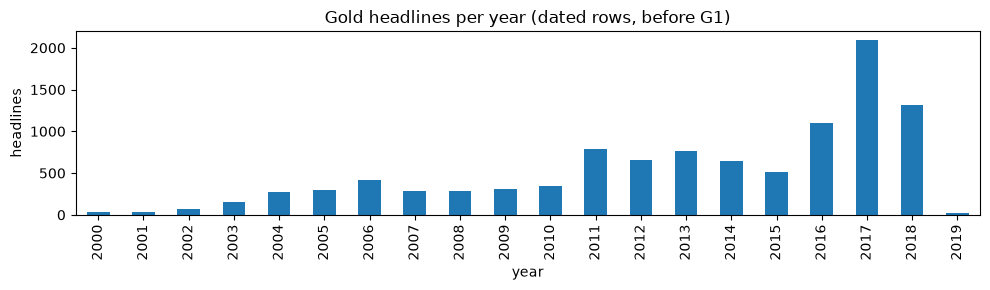

In [4]:
shares = pd.DataFrame({"all dated": sg.label_shares(gold)}).T.map(sg.pct)
display(shares)
per_year = gold.groupby(gold["date"].dt.year).size()
ax = per_year.plot.bar(figsize=(10, 3), title="Gold headlines per year (dated rows, before G1)")
ax.set_xlabel("year")
ax.set_ylabel("headlines")
plt.tight_layout()
plt.show()

## Step 3: G1 deduplicate (before any split)

Normalised text = lower case, every run of punctuation, digits or other non-letters becomes a
space, spaces collapsed. Exact duplicates of that text are dropped (the earliest date is kept).
Then a headline whose token set has Jaccard >= 0.8 with a kept headline at most 3 days earlier
is dropped as a near-duplicate. Deduplicating before the split keeps repeated wire headlines
from sitting in both train and test (PREREG §10.4).

In [5]:
gold = sd.dedupe(gold, cfg.near_jaccard, cfg.window_days)
sg.g1_table(gold)

,year,rows,exact removed,near removed,kept
0,2000,30,0,0,30
1,2001,36,0,0,36
2,2002,74,0,0,74
3,2003,155,10,0,145
4,2004,272,39,0,233
5,2005,293,58,4,231
6,2006,423,66,2,355
7,2007,280,21,0,259
8,2008,290,46,4,240
9,2009,308,42,0,266


Because digits are stripped and exact matching is global (no date window), recurring
price-report templates collapse across years. The table shows how far each exact duplicate is from
the headline it repeats, and how often its Price Sentiment differs (the kept one is used).

In [6]:
sg.g1_exact_table(gold)

,gap,n,label differs
0,same day,8,0
1,1-3 days,21,0
2,4-30 days,179,3
3,over 30 days,868,21
4,all,1076,24


## Step 4: split by date (PREREG §2.5)

Default: train <= 2012, validation 2013-2015, test 2016+. If the default test split held fewer
than 1,500 kept headlines the code would switch to 2011 / 2012-2014 / 2015+; the choice is made
from the count alone, before any model. Then we check that no normalised text is in two splits.

In [7]:
kept_mask = gold["keep"]
choice = sd.choose_split(
    gold.loc[kept_mask, "date"], cfg.default_split, cfg.fallback_split, cfg.min_test
)
gold["split"] = sd.assign_split(gold["date"], choice.train_last, choice.val_last)
sd.assert_disjoint(gold.loc[kept_mask, "norm"], gold.loc[kept_mask, "split"])
print(
    f"chosen: {choice.name} (train <= {choice.train_last}, validation <= {choice.val_last}); "
    f"default test count {choice.test_count_default:,} vs minimum {cfg.min_test:,}"
)
pd.Series(choice.counts, name="kept headlines").to_frame()

chosen: default (train <= 2012-12-31, validation <= 2015-12-31); default test count 3,943 vs minimum 1,500


,kept headlines
train,3536
validation,1792
test,3943


## Step 5: prices (Dukascopy XAUUSD D1 bid)

Bars start at 00:00 UTC. The reader stops at the first bar on or after 2026-01-10 (the lockbox).
Each short Sunday-evening bar is merged into Monday (open = Sunday open, high/low = max/min,
close = Monday close, volume = sum). 2000-2002 are dropped from the prices (rounded prices,
impossible OHLC) but kept in the trading calendar used to align those years' headlines. Then
OHLC sanity is checked again and the Garman-Klass variance is added. These plots show prices
only; nothing here touches the headlines.

,value
sunday_bars,1173
sunday_merged,1173
sunday_dropped,0
saturday_bars,0
bars_raw,7918
bars_from_first,5988
first_price_day,2003-01-02
last_price_day,2026-01-09
ohlc_violations,0
gk_nonpositive,0


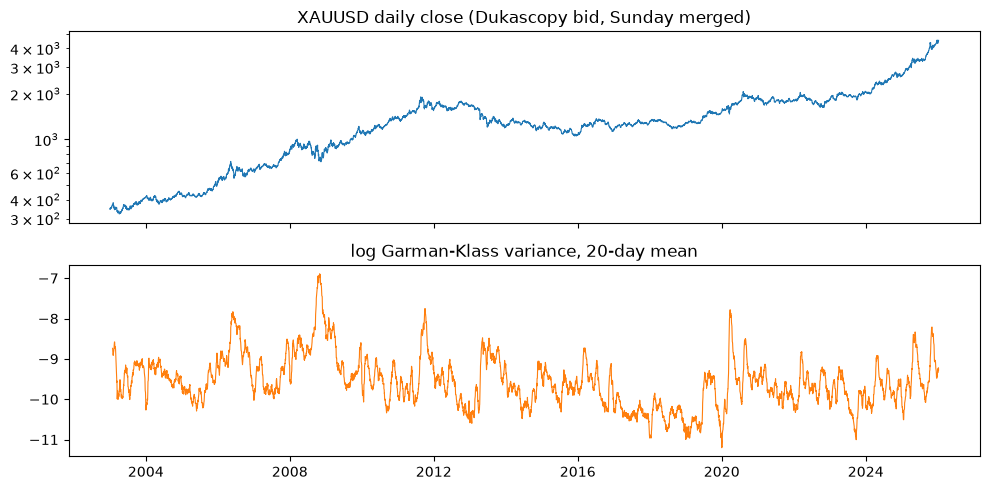

In [8]:
calendar, prices, price_stats, violations = sd.build_prices(cfg)
display(pd.Series(price_stats, name="value").to_frame())
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(prices["date"], prices["close"], lw=0.8)
axes[0].set_yscale("log")
axes[0].set_title("XAUUSD daily close (Dukascopy bid, Sunday merged)")
axes[1].plot(prices["date"], prices["log_gk"].rolling(20).mean(), lw=0.8, color="tab:orange")
axes[1].set_title("log Garman-Klass variance, 20-day mean")
plt.tight_layout()
plt.show()

## G3: align headline dates to price days

A headline dated on a weekend or a weekday without a bar moves to the next price day
(`trade_date`). Only the calendar (which dates have a bar) is used, never a price.

In [9]:
gold["trade_date"] = sd.align_trade_dates(gold["date"], calendar)
gold["moved"] = gold["trade_date"].ne(gold["date"])
kept = gold.loc[gold["keep"]]
sg.g3_table(kept)

,year,headlines,weekend,"weekday, no bar",moved
0,2000,30,1,0,1
1,2001,36,0,0,0
2,2002,74,2,0,2
3,2003,145,2,0,2
4,2004,233,0,0,0
5,2005,231,1,0,1
6,2006,355,10,0,10
7,2007,259,5,0,5
8,2008,240,11,0,11
9,2009,266,17,0,17


## G4: label balance and class weights

Class shares per split; the class weights for the weighted cross-entropy come from train only:
w_c = n / (K * n_c).

In [10]:
display(sg.g4_table(kept))
weights = sg.class_weights(kept.loc[kept["split"] == "train", "label"])
pd.Series(weights, name="weight (train only)").to_frame()

,split,headlines,negative,neutral,positive,of which none,first,last
0,train,3536,35.1%,19.5%,45.4%,16.8%,2000-02-15,2012-12-31
1,validation,1792,37.7%,25.8%,36.6%,22.0%,2013-01-02,2015-12-31
2,test,3943,34.3%,27.1%,38.7%,22.7%,2016-01-01,2019-02-01


,weight (train only)
negative,0.950538
neutral,1.705740
positive,0.734372


## G5: coverage

Price days from 2003 (to the last headline's trade date) with no kept headline, per year.
Counts only.

,year,price days,zero-headline days,share
0,2003,260,149,57.3%
1,2004,262,113,43.1%
2,2005,260,118,45.4%
3,2006,260,78,30.0%
4,2007,261,86,33.0%
5,2008,262,104,39.7%
6,2009,261,94,36.0%
7,2010,261,88,33.7%
8,2011,260,39,15.0%
9,2012,261,32,12.3%


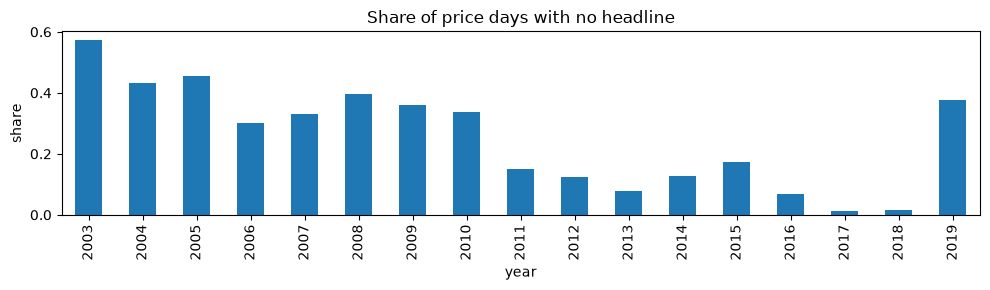

In [11]:
g5 = sg.g5_table(kept, calendar, cfg.price_first)
display(g5)
share = g5.set_index("year")["zero-headline days"] / g5.set_index("year")["price days"]
ax = share.plot.bar(figsize=(10, 3), title="Share of price days with no headline")
ax.set_ylabel("share")
plt.tight_layout()
plt.show()

## G2: price cross-check

Dukascopy against an independent daily series on common dates from 2003 (pass: close correlation
>= 0.99). The Stooq file could not be downloaded, so G2 is pending until Fadi's MT5 D1 export.

In [12]:
other = sg.read_stooq(cfg.files["stooq"].path, cfg.price_stop) if status["stooq"] == "ok" else None
sg.g2_crosscheck(
    prices, other, cfg.price_first, cfg.g2_min_close_corr, cfg.g2_return_diff, cfg.g2_list
)

{'status': 'pending'}

## FinancialPhraseBank (Sentences_AllAgree)

Used only for stage-1 training (S3); its labels are from an equity investor's point of view.

In [13]:
fpb = sd.load_fpb(cfg.files["fpb"].path)
print(f"rows {len(fpb):,}")
fpb["label"].value_counts(normalize=True).reindex(sd.LABELS).map(sg.pct).to_frame("share")

rows 2,264


,share
label,
negative,13.4%
neutral,61.4%
positive,25.2%


## Reproducibility check

The command-line pipeline (`sd.build`) must give the same headline frame as the steps above, the
saved parquet files must equal it, and `docs/sentiment/gates.md` must equal the report rendered
from the saved files. Only booleans are printed.

In [14]:
built = sd.build(cfg)
cols = ["row_id", "date", "keep", "dup_exact", "dup_near", "dup_of", "split", "trade_date"]
same_steps = built.gold[cols].equals(gold[cols])
processed = sd.load_processed(cfg)
same_saved = processed["gold"][cols].equals(built.gold[cols])
report = sg.render(sg.summarise(processed, cfg, other), cfg)
same_report = report == cfg.report.read_text(encoding="utf-8")
print("notebook steps == build():", same_steps)
print("saved parquet == build():", same_saved)
print("gates.md == rendered from saved files:", same_report)
assert same_steps and same_saved and same_report

notebook steps == build(): True
saved parquet == build(): True
gates.md == rendered from saved files: True
